# Analyse des tendances musicales : rap ivoirien

Récupération d'une playlist via l'API Spotify, ajout des caractéristiques audio via l'API ReccoBeats, nettoyage avec Pandas, puis visualisations (popularité, tempo, énergie, danceability, solo contre featuring).

In [132]:
import os
import requests

# Les identifiants Spotify ne sont jamais écrits dans le code : ils viennent du fichier .env
# (voir README) ou des variables d'environnement.
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

url = "https://accounts.spotify.com/api/token"
herders = {
    "Content-Type": "application/x-www-form-urlencoded"
}
data = { "grant_type": "client_credentials",
         "client_id": os.environ["SPOTIFY_CLIENT_ID"],
         "client_secret": os.environ["SPOTIFY_CLIENT_SECRET"]}
response = requests.post(url, headers=herders, data=data)
token = response.json().get("access_token")
print("Token obtenu :", token is not None)


Token obtenu : True


In [133]:
import json
url=" https://api.spotify.com/v1/playlists/06rNpYURpjfHXT7ZqByQmq"
headers ={'Authorization': f'Bearer {token}'}
response = requests.get(url, headers=headers)
print(json.dumps(response.json(), indent=2))
with open("playlist_full.json", "w", encoding="utf-8") as f:
    json.dump(response.json(), f, indent=2, ensure_ascii=False)

In [134]:
import requests
import json

def spoti(token):
    url = "https://api.spotify.com/v1/playlists/06rNpYURpjfHXT7ZqByQmq/tracks"
    headers = {'Authorization': f'Bearer {token}'}
    params = {"limit": 100}  

    all_tracks = []
 
    while url:  
        response = requests.get(url, headers=headers, params=params)
        data = response.json()

   
        all_tracks.extend(data["items"])

      
        url = data.get("next")


    with open("playlist.json", "w", encoding="utf-8") as f:
        json.dump(all_tracks, f, indent=2, ensure_ascii=False)

    return all_tracks


tracks = spoti(token)
print(f"Nombre total de morceaux récupérés : {len(tracks)}")


Nombre total de morceaux récupérés : 202


In [135]:
tracks

In [136]:
import requests
import json

with open("playlist.json", "r", encoding="utf-8") as f:
    data = json.load(f)   

full_data = []
for i in range(0, len(data), 40):   
    track_ids = []
    for item in data[i:i+40]:      
        track_name = item['track']['name']
        track_id = item['track']['id']
        track_ids.append(track_id)

    url = "https://api.reccobeats.com/v1/audio-features"
    headers = {"Accept": "application/json"}
    params = {"ids": ",".join(track_ids)}  
    response = requests.get(url, headers=headers, params=params)
    full_data.append(response.json())


In [137]:
import pandas as pd

In [138]:
len(full_data)

6

In [139]:
# creer un datafrmae reccobeats et spotify du genre liste de dictionnaires


reccobeats_list = []
for i in full_data:
    for track in i['content']:
        reccobeats_list.append(track)

spotify_list = []
with open("playlist.json", "r", encoding="utf-8") as f:
    data = json.load(f)   

for item in data:  
    track_info = {
        'id': item['track']['id'],
        'name': item['track']['name'],
        'duration_ms': item['track']['duration_ms'],
        'popularity': item['track']['popularity'],
        'artists': [artist['name'] for artist in item['track']['artists']]
    }
    spotify_list.append(track_info)



In [140]:
len(reccobeats_list)

119

In [141]:
spotify_list

[{'id': '1kPc4ez3x7fY8ChByxRKnv',
  'name': 'NOUVEAU BOSS',
  'duration_ms': 192253,
  'popularity': 50,
  'artists': ['Himra']},
 {'id': '3XfcxNZBqH041yy5kLHh27',
  'name': 'VETEMENTS',
  'duration_ms': 188307,
  'popularity': 53,
  'artists': ['Himra']},
 {'id': '2c7BLx2TazIh3rEAz16V8h',
  'name': 'DAGBACHI',
  'duration_ms': 193714,
  'popularity': 49,
  'artists': ['Himra']},
 {'id': '139t4sGtV02KC1xLJlQ535',
  'name': 'Freestyle Drill Ivoire 5',
  'duration_ms': 178285,
  'popularity': 47,
  'artists': ['Himra']},
 {'id': '5AlVu2mPffRpH5CEbXqEm7',
  'name': 'DACHIBA KOUMGBA TCHAIBA',
  'duration_ms': 273373,
  'popularity': 47,
  'artists': ['HIMRA']},
 {'id': '1OD1skHTgSSLF8lmWTqbB6',
  'name': 'YOROBO DRILL ACTE 3',
  'duration_ms': 169510,
  'popularity': 53,
  'artists': ['Himra']},
 {'id': '5Y9hDVCrBsctHIL5FRAFHm',
  'name': 'Yorobo Drill Acte 1',
  'duration_ms': 212192,
  'popularity': 38,
  'artists': ['Himra']},
 {'id': '5BvecphcYmA7vbIcrn9GmP',
  'name': 'SOLO',
  'durat

In [142]:
reccobeats_list

[{'id': 'ac996c05-3615-4b2d-a6bb-178f5e3a908d',
  'href': 'https://open.spotify.com/track/4PaxqJUKkd17YnOYTPX0b3',
  'acousticness': 0.142,
  'danceability': 0.47,
  'energy': 0.444,
  'instrumentalness': 0.000186,
  'key': 1,
  'liveness': 0.137,
  'loudness': -9.9,
  'mode': 0,
  'speechiness': 0.0507,
  'tempo': 139.909,
  'valence': 0.514},
 {'id': '258f1a4d-e0b0-4864-832e-d7774c3ace3b',
  'href': 'https://open.spotify.com/track/109tSPuGfD2ZnAVeTTPMYc',
  'acousticness': 0.0142,
  'danceability': 0.721,
  'energy': 0.563,
  'instrumentalness': 0.0,
  'key': 11,
  'liveness': 0.331,
  'loudness': -8.54,
  'mode': 0,
  'speechiness': 0.0652,
  'tempo': 144.972,
  'valence': 0.422},
 {'id': '7cf4d79b-6994-45fb-83bb-94377e913ae7',
  'href': 'https://open.spotify.com/track/5D963efvNjdYQ4RWDbEnfh',
  'acousticness': 0.0559,
  'danceability': 0.785,
  'energy': 0.64,
  'instrumentalness': 0.0,
  'key': 8,
  'liveness': 0.241,
  'loudness': -5.94,
  'mode': 1,
  'speechiness': 0.138,
  'te

### Transformation de nos listes en Dataframe

In [143]:

import pandas as pd 
df_reccobeats = pd.DataFrame(reccobeats_list)
df_spotify = pd.DataFrame(spotify_list)

### Afficher le dataframe reccobeats

In [144]:
df_reccobeats

,id,href,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence
0,ac996c05-3615-4b2d-a6bb-178f5e3a908d,https://open.spotify.com/track/4PaxqJUKkd17YnO...,0.1420,0.470,0.444,0.000186,1,0.1370,-9.900,0,0.0507,139.909,0.514
1,258f1a4d-e0b0-4864-832e-d7774c3ace3b,https://open.spotify.com/track/109tSPuGfD2ZnAV...,0.0142,0.721,0.563,0.000000,11,0.3310,-8.540,0,0.0652,144.972,0.422
2,7cf4d79b-6994-45fb-83bb-94377e913ae7,https://open.spotify.com/track/5D963efvNjdYQ4R...,0.0559,0.785,0.640,0.000000,8,0.2410,-5.940,1,0.1380,144.000,0.426
3,eb5118e9-130b-4a11-a7da-74f523f96cc2,https://open.spotify.com/track/6R4ybKKraKGn20h...,0.4190,0.835,0.694,0.000000,8,0.1730,-8.888,1,0.3900,141.895,0.502
4,e22ae0bf-1455-41bc-9a91-01a9dfe605d0,https://open.spotify.com/track/5Y9hDVCrBsctHIL...,0.2250,0.500,0.577,0.000000,8,0.0874,-10.003,0,0.1760,101.193,0.307
...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,1146d048-4713-4da9-9f0a-7071ff29a01d,https://open.spotify.com/track/1BSFpUxK3wmEhiG...,0.2060,0.714,0.694,0.000066,1,0.0605,-6.353,1,0.2780,142.080,0.522
115,bf8a3768-9b91-47b6-a72b-2cc0cbbef175,https://open.spotify.com/track/48L3AhhbtTxAdeK...,0.2130,0.504,0.801,0.000000,1,0.1420,-6.974,1,0.2060,89.381,0.285
116,f144ec02-f9d6-4ec9-baa3-cb9c879ecace,https://open.spotify.com/track/7FRniN2WWFoH77P...,0.0234,0.731,0.745,0.000000,11,0.2870,-7.852,1,0.2780,130.057,0.414
117,ec98521c-a75d-409d-b35d-c0724c039c30,https://open.spotify.com/track/2A5qmDuRrn9Wvac...,0.2170,0.755,0.931,0.000167,0,0.8610,-5.313,0,0.1910,144.094,0.875


In [145]:
# avec un split on va recupere que les id dans href
df_reccobeats = pd.DataFrame(reccobeats_list)
df_reccobeats["spotify_id"] = df_reccobeats["href"].apply(lambda x: x.split("/")[-1])


In [146]:
# on a mainteant le spotify id
df_reccobeats


,id,href,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,spotify_id
0,ac996c05-3615-4b2d-a6bb-178f5e3a908d,https://open.spotify.com/track/4PaxqJUKkd17YnO...,0.1420,0.470,0.444,0.000186,1,0.1370,-9.900,0,0.0507,139.909,0.514,4PaxqJUKkd17YnOYTPX0b3
1,258f1a4d-e0b0-4864-832e-d7774c3ace3b,https://open.spotify.com/track/109tSPuGfD2ZnAV...,0.0142,0.721,0.563,0.000000,11,0.3310,-8.540,0,0.0652,144.972,0.422,109tSPuGfD2ZnAVeTTPMYc
2,7cf4d79b-6994-45fb-83bb-94377e913ae7,https://open.spotify.com/track/5D963efvNjdYQ4R...,0.0559,0.785,0.640,0.000000,8,0.2410,-5.940,1,0.1380,144.000,0.426,5D963efvNjdYQ4RWDbEnfh
3,eb5118e9-130b-4a11-a7da-74f523f96cc2,https://open.spotify.com/track/6R4ybKKraKGn20h...,0.4190,0.835,0.694,0.000000,8,0.1730,-8.888,1,0.3900,141.895,0.502,6R4ybKKraKGn20hHkHvPuQ
4,e22ae0bf-1455-41bc-9a91-01a9dfe605d0,https://open.spotify.com/track/5Y9hDVCrBsctHIL...,0.2250,0.500,0.577,0.000000,8,0.0874,-10.003,0,0.1760,101.193,0.307,5Y9hDVCrBsctHIL5FRAFHm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,1146d048-4713-4da9-9f0a-7071ff29a01d,https://open.spotify.com/track/1BSFpUxK3wmEhiG...,0.2060,0.714,0.694,0.000066,1,0.0605,-6.353,1,0.2780,142.080,0.522,1BSFpUxK3wmEhiGCc1hJLk
115,bf8a3768-9b91-47b6-a72b-2cc0cbbef175,https://open.spotify.com/track/48L3AhhbtTxAdeK...,0.2130,0.504,0.801,0.000000,1,0.1420,-6.974,1,0.2060,89.381,0.285,48L3AhhbtTxAdeKoLjeApz
116,f144ec02-f9d6-4ec9-baa3-cb9c879ecace,https://open.spotify.com/track/7FRniN2WWFoH77P...,0.0234,0.731,0.745,0.000000,11,0.2870,-7.852,1,0.2780,130.057,0.414,7FRniN2WWFoH77P3gFf51r
117,ec98521c-a75d-409d-b35d-c0724c039c30,https://open.spotify.com/track/2A5qmDuRrn9Wvac...,0.2170,0.755,0.931,0.000167,0,0.8610,-5.313,0,0.1910,144.094,0.875,2A5qmDuRrn9Wvac7mJrovL


In [147]:
df_reccobeats.drop(columns=["href"], inplace=True )
df_reccobeats

,id,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,spotify_id
0,ac996c05-3615-4b2d-a6bb-178f5e3a908d,0.1420,0.470,0.444,0.000186,1,0.1370,-9.900,0,0.0507,139.909,0.514,4PaxqJUKkd17YnOYTPX0b3
1,258f1a4d-e0b0-4864-832e-d7774c3ace3b,0.0142,0.721,0.563,0.000000,11,0.3310,-8.540,0,0.0652,144.972,0.422,109tSPuGfD2ZnAVeTTPMYc
2,7cf4d79b-6994-45fb-83bb-94377e913ae7,0.0559,0.785,0.640,0.000000,8,0.2410,-5.940,1,0.1380,144.000,0.426,5D963efvNjdYQ4RWDbEnfh
3,eb5118e9-130b-4a11-a7da-74f523f96cc2,0.4190,0.835,0.694,0.000000,8,0.1730,-8.888,1,0.3900,141.895,0.502,6R4ybKKraKGn20hHkHvPuQ
4,e22ae0bf-1455-41bc-9a91-01a9dfe605d0,0.2250,0.500,0.577,0.000000,8,0.0874,-10.003,0,0.1760,101.193,0.307,5Y9hDVCrBsctHIL5FRAFHm
...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,1146d048-4713-4da9-9f0a-7071ff29a01d,0.2060,0.714,0.694,0.000066,1,0.0605,-6.353,1,0.2780,142.080,0.522,1BSFpUxK3wmEhiGCc1hJLk
115,bf8a3768-9b91-47b6-a72b-2cc0cbbef175,0.2130,0.504,0.801,0.000000,1,0.1420,-6.974,1,0.2060,89.381,0.285,48L3AhhbtTxAdeKoLjeApz
116,f144ec02-f9d6-4ec9-baa3-cb9c879ecace,0.0234,0.731,0.745,0.000000,11,0.2870,-7.852,1,0.2780,130.057,0.414,7FRniN2WWFoH77P3gFf51r
117,ec98521c-a75d-409d-b35d-c0724c039c30,0.2170,0.755,0.931,0.000167,0,0.8610,-5.313,0,0.1910,144.094,0.875,2A5qmDuRrn9Wvac7mJrovL


### Afficher le dataframe spotify

In [148]:
df_spotify

,id,name,duration_ms,popularity,artists
0,1kPc4ez3x7fY8ChByxRKnv,NOUVEAU BOSS,192253,50,[Himra]
1,3XfcxNZBqH041yy5kLHh27,VETEMENTS,188307,53,[Himra]
2,2c7BLx2TazIh3rEAz16V8h,DAGBACHI,193714,49,[Himra]
3,139t4sGtV02KC1xLJlQ535,Freestyle Drill Ivoire 5,178285,47,[Himra]
4,5AlVu2mPffRpH5CEbXqEm7,DACHIBA KOUMGBA TCHAIBA,273373,47,[HIMRA]
...,...,...,...,...,...
197,0cSQFKhK282vmsrGFdnepb,On se met bien,221866,23,"[Fior 2 Bior, Didi B]"
198,4aV2PjsVYk9LH2c9VglQaY,Arc de triomphe,205263,36,"[DJ KEROZEN, Didi B]"
199,2kbX0sWoep1pOzUvCWK4D6,Din Kou Din,175631,30,"[Toofan, Didi B]"
200,2A5qmDuRrn9Wvac7mJrovL,3023,150000,26,[Didi B]


### Vérification avant analyse 

In [149]:
# afficher les types des colonnes des dataframes
df_reccobeats.dtypes


id                   object
acousticness        float64
danceability        float64
energy              float64
instrumentalness    float64
key                   int64
liveness            float64
loudness            float64
mode                  int64
speechiness         float64
tempo               float64
valence             float64
spotify_id           object
dtype: object

In [150]:
df_spotify.dtypes

id             object
name           object
duration_ms     int64
popularity      int64
artists        object
dtype: object

In [151]:
df_spotify["artists"] = df_spotify["artists"].apply(
    lambda x: ", ".join(x) if isinstance(x, list) else str(x)
)


In [152]:
# Vérifier si nous avons des doublons 
df_reccobeats.duplicated().sum()


np.int64(0)

In [153]:
df_spotify.duplicated().sum()

np.int64(0)

In [154]:
df_spotify

,id,name,duration_ms,popularity,artists
0,1kPc4ez3x7fY8ChByxRKnv,NOUVEAU BOSS,192253,50,Himra
1,3XfcxNZBqH041yy5kLHh27,VETEMENTS,188307,53,Himra
2,2c7BLx2TazIh3rEAz16V8h,DAGBACHI,193714,49,Himra
3,139t4sGtV02KC1xLJlQ535,Freestyle Drill Ivoire 5,178285,47,Himra
4,5AlVu2mPffRpH5CEbXqEm7,DACHIBA KOUMGBA TCHAIBA,273373,47,HIMRA
...,...,...,...,...,...
197,0cSQFKhK282vmsrGFdnepb,On se met bien,221866,23,"Fior 2 Bior, Didi B"
198,4aV2PjsVYk9LH2c9VglQaY,Arc de triomphe,205263,36,"DJ KEROZEN, Didi B"
199,2kbX0sWoep1pOzUvCWK4D6,Din Kou Din,175631,30,"Toofan, Didi B"
200,2A5qmDuRrn9Wvac7mJrovL,3023,150000,26,Didi B


In [155]:
# Verifions si nous avons des valerus manquantes
df_spotify.isnull().sum()

id             0
name           0
duration_ms    0
popularity     0
artists        0
dtype: int64

In [156]:
df_reccobeats.isnull().sum()

id                  0
acousticness        0
danceability        0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
valence             0
spotify_id          0
dtype: int64

In [157]:
# on va maintenant fusionner les deux dataset sur l id en commun(spotify id = id)
df_spotify
df_reccobeats
df= pd.merge(df_spotify, df_reccobeats, left_on='id', right_on='spotify_id', how="inner")

In [158]:
df

,id_x,name,duration_ms,popularity,artists,id_y,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,spotify_id
0,1kPc4ez3x7fY8ChByxRKnv,NOUVEAU BOSS,192253,50,Himra,ed7c14d5-a4bf-46a6-a64c-ae2dc7d2e69a,0.1460,0.780,0.674,0.000000,6,0.3340,-4.673,1,0.0488,156.996,0.714,1kPc4ez3x7fY8ChByxRKnv
1,3XfcxNZBqH041yy5kLHh27,VETEMENTS,188307,53,Himra,f8b915b2-dc06-4f6e-8312-3a34412a7fd8,0.3400,0.520,0.648,0.000018,8,0.2240,-6.790,0,0.0555,96.350,0.798,3XfcxNZBqH041yy5kLHh27
2,2c7BLx2TazIh3rEAz16V8h,DAGBACHI,193714,49,Himra,9054b8ae-6cb5-4f95-b1d3-0e3a79ba4302,0.2480,0.734,0.935,0.000000,8,0.5540,-2.759,1,0.2980,139.889,0.716,2c7BLx2TazIh3rEAz16V8h
3,1OD1skHTgSSLF8lmWTqbB6,YOROBO DRILL ACTE 3,169510,53,Himra,606188d7-f0fb-45b9-a561-bd46882a229b,0.1340,0.523,0.821,0.000000,1,0.0986,-4.488,1,0.1550,96.334,0.603,1OD1skHTgSSLF8lmWTqbB6
4,5Y9hDVCrBsctHIL5FRAFHm,Yorobo Drill Acte 1,212192,38,Himra,e22ae0bf-1455-41bc-9a91-01a9dfe605d0,0.2250,0.500,0.577,0.000000,8,0.0874,-10.003,0,0.1760,101.193,0.307,5Y9hDVCrBsctHIL5FRAFHm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,0cSQFKhK282vmsrGFdnepb,On se met bien,221866,23,"Fior 2 Bior, Didi B",d37bb721-e039-4abb-ae05-5cfd301c8c9e,0.4210,0.566,0.933,0.000000,11,0.5940,-5.235,0,0.2850,159.027,0.765,0cSQFKhK282vmsrGFdnepb
115,4aV2PjsVYk9LH2c9VglQaY,Arc de triomphe,205263,36,"DJ KEROZEN, Didi B",de7b5f67-7f4e-4422-a196-eb3015df6c00,0.1730,0.595,0.722,0.000000,10,0.1260,-5.739,1,0.2830,133.034,0.745,4aV2PjsVYk9LH2c9VglQaY
116,2kbX0sWoep1pOzUvCWK4D6,Din Kou Din,175631,30,"Toofan, Didi B",c45c92ce-6be4-4644-a970-a122a5393441,0.2670,0.724,0.776,0.000000,6,0.1010,-5.462,0,0.0740,94.144,0.811,2kbX0sWoep1pOzUvCWK4D6
117,2A5qmDuRrn9Wvac7mJrovL,3023,150000,26,Didi B,ec98521c-a75d-409d-b35d-c0724c039c30,0.2170,0.755,0.931,0.000167,0,0.8610,-5.313,0,0.1910,144.094,0.875,2A5qmDuRrn9Wvac7mJrovL


## LES VISUALISATIONS

In [159]:
df["n_artists"] = df["artists"].apply(lambda x: len(x.split(", ")))
df["type"] = df["n_artists"].apply(lambda n: "solo" if n == 1 else "feat")


In [160]:
df

,id_x,name,duration_ms,popularity,artists,id_y,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,spotify_id,n_artists,type
0,1kPc4ez3x7fY8ChByxRKnv,NOUVEAU BOSS,192253,50,Himra,ed7c14d5-a4bf-46a6-a64c-ae2dc7d2e69a,0.1460,0.780,0.674,0.000000,6,0.3340,-4.673,1,0.0488,156.996,0.714,1kPc4ez3x7fY8ChByxRKnv,1,solo
1,3XfcxNZBqH041yy5kLHh27,VETEMENTS,188307,53,Himra,f8b915b2-dc06-4f6e-8312-3a34412a7fd8,0.3400,0.520,0.648,0.000018,8,0.2240,-6.790,0,0.0555,96.350,0.798,3XfcxNZBqH041yy5kLHh27,1,solo
2,2c7BLx2TazIh3rEAz16V8h,DAGBACHI,193714,49,Himra,9054b8ae-6cb5-4f95-b1d3-0e3a79ba4302,0.2480,0.734,0.935,0.000000,8,0.5540,-2.759,1,0.2980,139.889,0.716,2c7BLx2TazIh3rEAz16V8h,1,solo
3,1OD1skHTgSSLF8lmWTqbB6,YOROBO DRILL ACTE 3,169510,53,Himra,606188d7-f0fb-45b9-a561-bd46882a229b,0.1340,0.523,0.821,0.000000,1,0.0986,-4.488,1,0.1550,96.334,0.603,1OD1skHTgSSLF8lmWTqbB6,1,solo
4,5Y9hDVCrBsctHIL5FRAFHm,Yorobo Drill Acte 1,212192,38,Himra,e22ae0bf-1455-41bc-9a91-01a9dfe605d0,0.2250,0.500,0.577,0.000000,8,0.0874,-10.003,0,0.1760,101.193,0.307,5Y9hDVCrBsctHIL5FRAFHm,1,solo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,0cSQFKhK282vmsrGFdnepb,On se met bien,221866,23,"Fior 2 Bior, Didi B",d37bb721-e039-4abb-ae05-5cfd301c8c9e,0.4210,0.566,0.933,0.000000,11,0.5940,-5.235,0,0.2850,159.027,0.765,0cSQFKhK282vmsrGFdnepb,2,feat
115,4aV2PjsVYk9LH2c9VglQaY,Arc de triomphe,205263,36,"DJ KEROZEN, Didi B",de7b5f67-7f4e-4422-a196-eb3015df6c00,0.1730,0.595,0.722,0.000000,10,0.1260,-5.739,1,0.2830,133.034,0.745,4aV2PjsVYk9LH2c9VglQaY,2,feat
116,2kbX0sWoep1pOzUvCWK4D6,Din Kou Din,175631,30,"Toofan, Didi B",c45c92ce-6be4-4644-a970-a122a5393441,0.2670,0.724,0.776,0.000000,6,0.1010,-5.462,0,0.0740,94.144,0.811,2kbX0sWoep1pOzUvCWK4D6,2,feat
117,2A5qmDuRrn9Wvac7mJrovL,3023,150000,26,Didi B,ec98521c-a75d-409d-b35d-c0724c039c30,0.2170,0.755,0.931,0.000167,0,0.8610,-5.313,0,0.1910,144.094,0.875,2A5qmDuRrn9Wvac7mJrovL,1,solo


In [161]:
df_himra = df[df["artists"].str.contains("Himra")]
df_didib = df[df["artists"].str.contains("Didi B")]


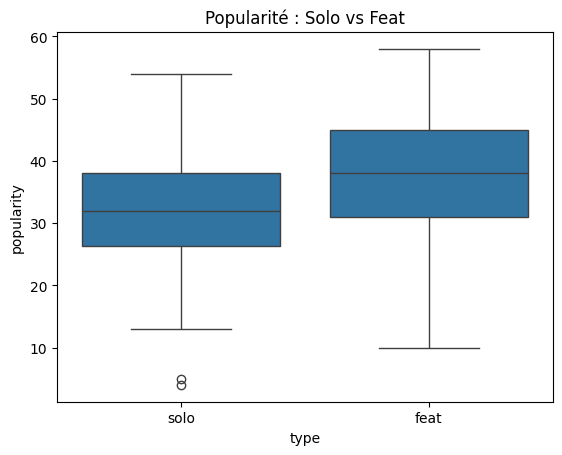

In [162]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="type", y="popularity")
plt.title("Popularité : Solo vs Feat")
plt.show()


On observe que les morceaux en featuring sont en moyenne plus populaires que les morceaux solo.
La médiane du groupe “feat” est plus élevée, et la distribution montre que les collaborations attirent un public plus large.
Cela confirme que dans le rap ivoire, les featurings augmentent la visibilité et la popularité des titres.

In [ ]:
# Définition du top 10 des morceaux les plus populaires (utilisé dans le graphique suivant)
top10 = df.sort_values("popularity", ascending=False).head(10).copy()


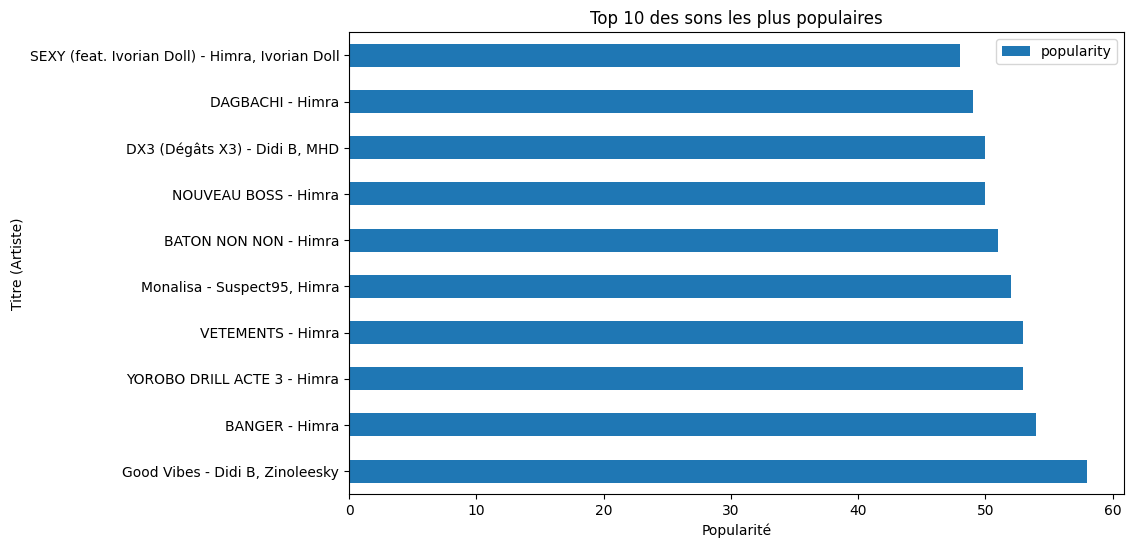

In [163]:
top10["label"] = top10["name"] + " - " + top10["artists"]

top10.plot(kind="barh", x="label", y="popularity", figsize=(10,6))
plt.title("Top 10 des sons les plus populaires")
plt.xlabel("Popularité")
plt.ylabel("Titre (Artiste)")
plt.show()


Ce graphique présente les 10 morceaux les plus populaires de mon dataset, avec leur titre et leur artiste.
Il permet d’identifier rapidement quels artistes dominent le top et quels titres rencontrent le plus de succès.
Les morceaux situés en haut du classement sont ceux qui ont obtenu les meilleures performances en termes de popularité.
Ce top 10 met en évidence les titres phares du rap ivoire présents dans ma playlist.

In [164]:
# on va comparer  maintenant sur la spcheeness


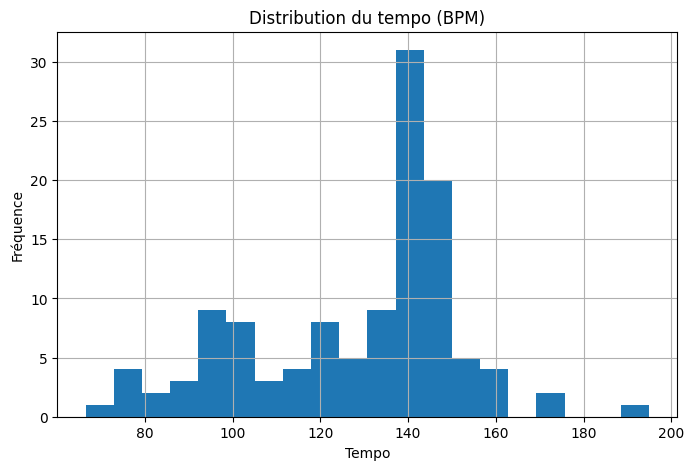

In [165]:
# HISTOGRAMME DU TEMPO LA DISTRIBUTION
df["tempo"].hist(bins=20, figsize=(8,5))
plt.title("Distribution du tempo (BPM)")
plt.xlabel("Tempo")
plt.ylabel("Fréquence")
plt.show()


La distribution du tempo (BPM) montre que la majorité des morceaux de mon dataset se situent dans une plage comprise entre environ 90 et 130 BPM. Cela correspond à des tempos moyens et rapides, typiques du rap ivoire moderne qui mise sur des rythmiques dynamiques et entraînantes.

On observe également que la distribution n’est pas uniforme : certaines plages de BPM sont beaucoup plus représentées que d’autres, ce qui montre une cohérence stylistique dans les productions analysées. Les morceaux très lents (<90 BPM) ou très rapides (>150 BPM) restent minoritaires.

Cela confirme que les artistes comme Didi B ou Himra favorisent des tempos énergiques adaptés à un public jeune et à des sonorités afro-urbaines.

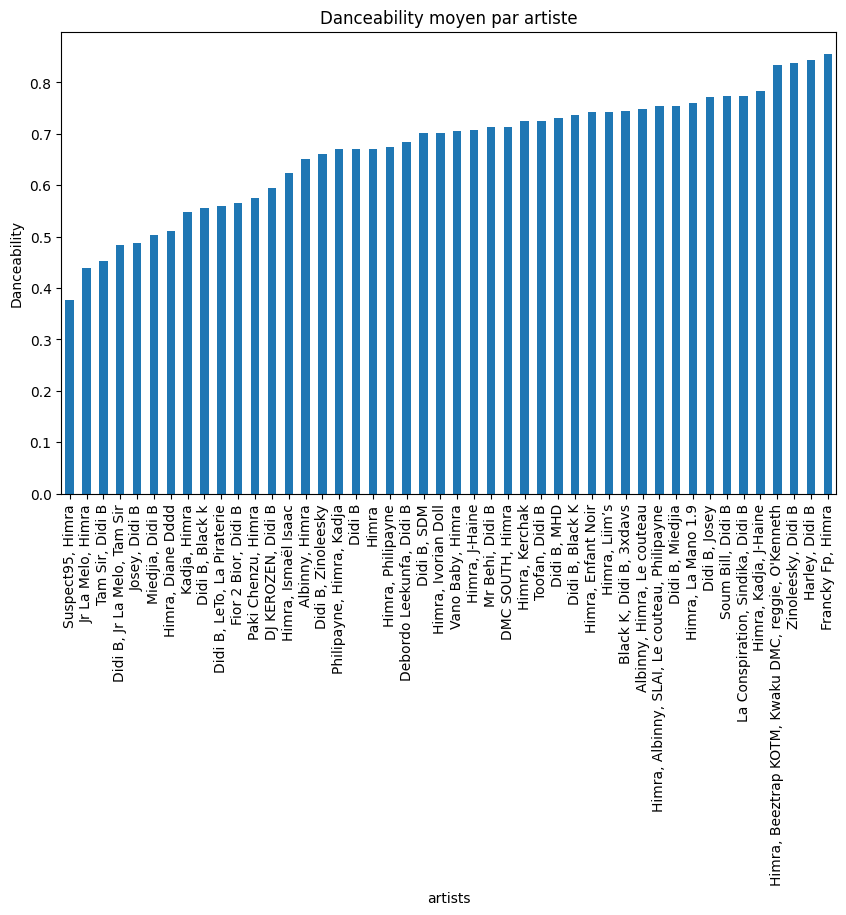

In [166]:
# MOYENNE DE DANCEABILITY PAR ARTISTE
df.groupby("artists")["danceability"].mean().sort_values().plot(
    kind="bar", figsize=(10,6)
)
plt.title("Danceability moyen par artiste")
plt.ylabel("Danceability")
plt.show()


Ce graphique montre la moyenne du danceability par artiste.
Les artistes avec une valeur plus élevée produisent des morceaux plus dansants comme himra, tandis que ceux avec une valeur plus basse ont un style plus calme.
On voit donc quels artistes ont les sons les plus “dansables” dans mon dataset et ceux qui ont un style plus posé.

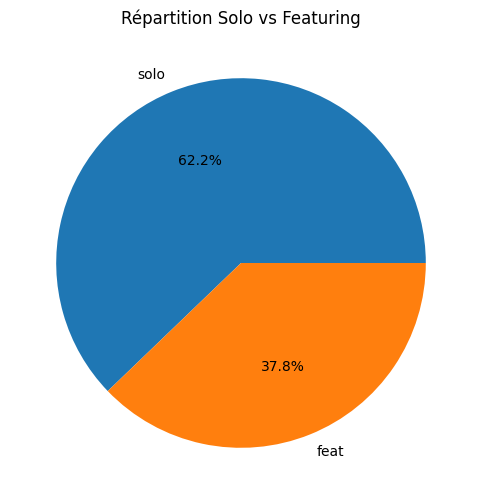

In [167]:
# PROPORTION SOLO VS FEAT
df["type"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", figsize=(6,6),
)
plt.title("Répartition Solo vs Featuring")
plt.ylabel("")
plt.show()


“La majorité des sons du rap ivoire sont des solos, mais les featurings représentent une part importante du style actuel.”

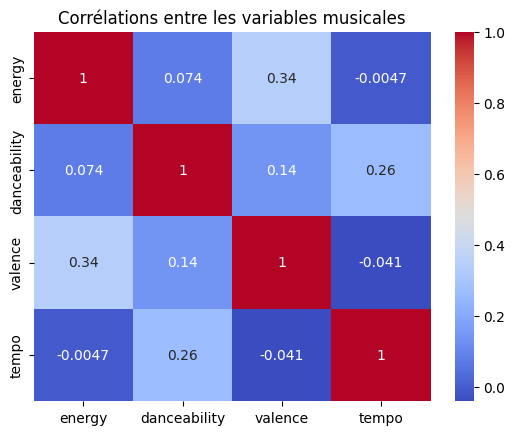

In [168]:
# UNE CORRELATION DE 4 VARIABLES
sns.heatmap(df[["energy","danceability","valence","tempo"]].corr(), 
            annot=True, cmap="coolwarm")
plt.title("Corrélations entre les variables musicales")
plt.show()


Cette heatmap montre les liens entre quatre caractéristiques musicales : l’énergie, la danceability, la valence et le tempo.
On observe quelles variables sont liées entre elles :

Une corrélation positive indique que les valeurs augmentent ensemble.

Une corrélation négative montre qu’elles évoluent en sens inverse.

Cela permet d’identifier quelles caractéristiques musicales vont souvent ensemble dans mon dataset.

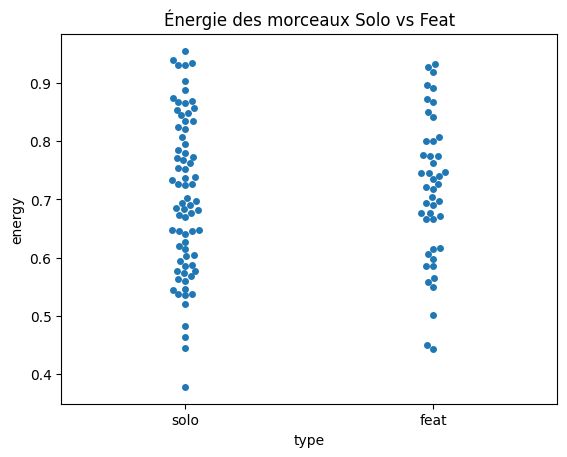

In [169]:
sns.swarmplot(data=df, x="type", y="energy")
plt.title("Énergie des morceaux Solo vs Feat")
plt.show()


Ce graphique compare l’énergie des morceaux solo et des morceaux en featuring.
On voit la répartition individuelle de chaque chanson :
si les points d’un groupe sont plus hauts, cela signifie que ce type de morceau est généralement plus énergique.
Ce visuel permet donc de voir rapidement si les featurings sont plus énergiques que les solos, ou inversement.

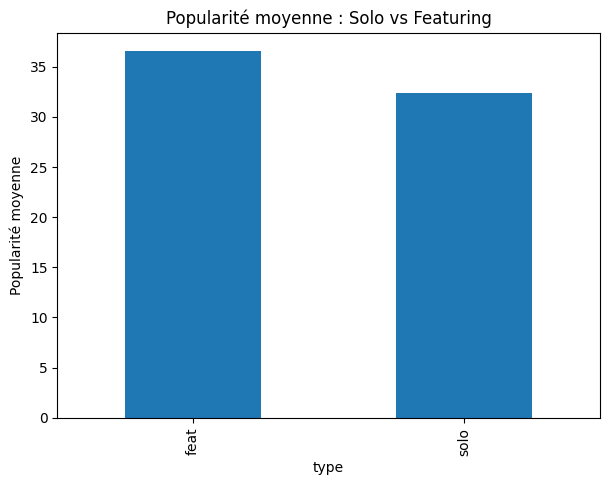

In [170]:
df.groupby("type")["popularity"].mean().plot(
    kind="bar", figsize=(7,5)
)
plt.title("Popularité moyenne : Solo vs Featuring")
plt.ylabel("Popularité moyenne")
plt.show()


Ce graphique compare la popularité moyenne des morceaux solo et des morceaux en featuring.
Il permet de voir rapidement quel type de morceau est le plus apprécié dans mon dataset :
si la barre “feat” est plus haute, les collaborations sont en moyenne plus populaires ;
si la barre “solo” domine, les titres individuels attirent davantage.

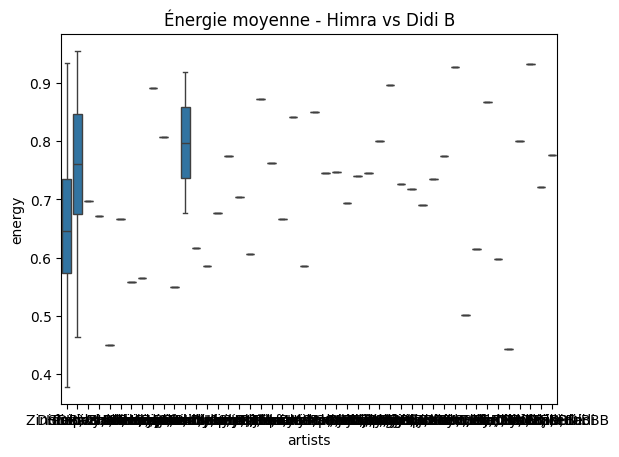

In [171]:
sns.boxplot(data=df[df["artists"].str.contains("Himra|Didi B")],
            x="artists", y="energy")
plt.title("Énergie moyenne - Himra vs Didi B")
plt.show()


Ce graphique compare le niveau d’énergie des morceaux de Himra et de Didi B.
Il permet de voir quel artiste produit en moyenne les titres les plus énergiques :
si la boîte de Himra est plus haute, cela signifie que ses sons sont globalement plus dynamiques ;
si celle de Didi B est plus élevée, alors ses morceaux sont en moyenne plus énergétiques.

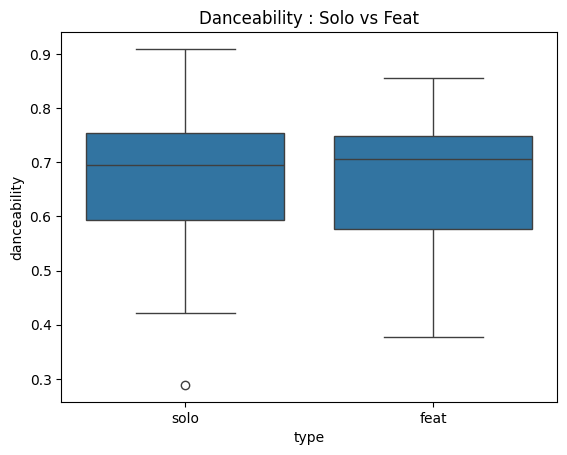

In [172]:
sns.boxplot(data=df, x="type", y="danceability")
plt.title("Danceability : Solo vs Feat")
plt.show()


Ce graphique compare à quel point les morceaux solo et les morceaux en featuring sont dansants.
Si la boîte du groupe “feat” est plus haute, cela signifie que les featurings sont généralement plus dansants ;
si c’est la boîte “solo”, alors les titres solo ont un niveau de danceability plus élevé.
Ce graphique permet donc de voir si les collaborations influencent le côté dansant des morceaux.

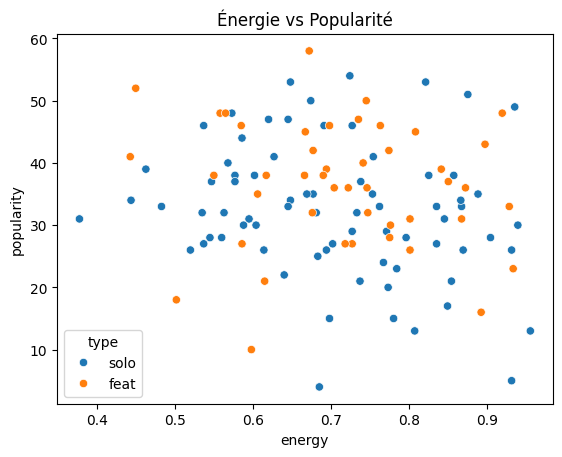

In [173]:
# ANALISE BIVARIEE
sns.scatterplot(data=df, x="energy", y="popularity", hue="type")
plt.title("Énergie vs Popularité")
plt.show()


Ce graphique montre le lien entre l’énergie d’un morceau et sa popularité.
Chaque point représente une chanson, et la couleur indique s’il s’agit d’un solo ou d’un featuring.
Il permet de voir si les morceaux très énergiques sont généralement plus populaires,
ou s’il n’y a pas de relation claire entre ces deux variables.

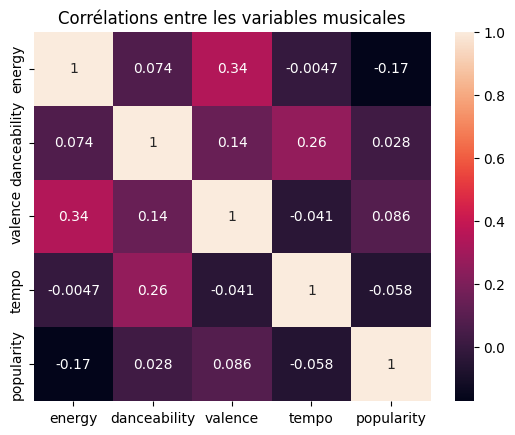

In [174]:
# ANALYSE MUTIVARIEE
sns.heatmap(df[["energy","danceability","valence","tempo","popularity"]].corr(), annot=True)
plt.title("Corrélations entre les variables musicales")
plt.show()


Cette heatmap présente les corrélations entre plusieurs caractéristiques musicales : l’énergie, la danceability, la valence, le tempo et la popularité.
Elle permet d’identifier rapidement quelles variables évoluent ensemble :
les valeurs positives indiquent une relation directe, tandis que les valeurs négatives montrent une relation inverse.
Cette analyse met en évidence les liens les plus forts entre les différentes dimensions musicales présentes dans mon dataset.

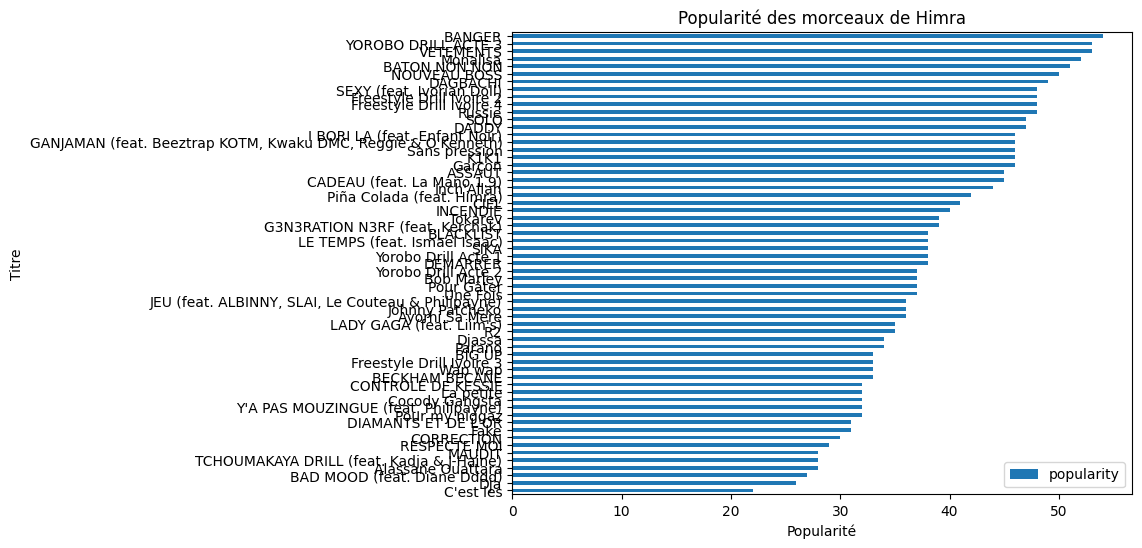

In [175]:
# POPULARITE DES MORCEAUX DE HIMRA
df_himra.sort_values("popularity").plot(
    x="name", y="popularity", kind="barh", figsize=(8,6)
)
plt.title("Popularité des morceaux de Himra")
plt.xlabel("Popularité")
plt.ylabel("Titre")
plt.show()


Ce graphique présente la popularité de chaque morceau de Himra dans mon dataset.
Il permet d’identifier quels titres sont les plus appréciés et lesquels le sont moins.
Les chansons situées en haut du graphique sont celles qui ont le plus de succès, tandis que celles en bas ont une popularité plus faible.
Cela donne une vue d’ensemble sur les performances musicales de Himra.